In [18]:
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent

import pandas as pd

# ============================================================
# 0. 데이터 불러오기: 2-5 train_test_comparison에서 제거된 이상치까지 반영된 데이터셋
# ============================================================

train = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '3_train_clean3.parquet')
val = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '3_val_clean3.parquet')

train_kf_oof = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '0_kf_oof_train2_index_fixed.parquet')

print(train.shape, val.shape, train_kf_oof.shape)

from sklearn import set_config
set_config(display='text')
# scikit-learn의 HTML 출력 과정에서 발생한 cp949 간 UTF-8 충돌 때문에 넣는 코드

(616293, 35) (133316, 35) (616293, 40)


In [2]:
# ============================================================
# 0. 라이브러리 불러오기
# ============================================================

import numpy as np
import optuna

from catboost import CatBoostRegressor
from sklearn.metrics import root_mean_squared_error

c:\Users\20162180\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# ============================================================
# 1. 컬럼군 정의
# ============================================================

target_col = 'target_maxrise_6h'  # 모델링 학습부터는 반드시 빼내야 함

# 수위 컬럼군
wl_cols = [
    'wl_t',
    'wl_t_minus_1h',
    'wl_t_minus_3h',
    'wl_t_minus_6h',
    'wl_t_minus_12h',
    'wl_t_minus_24h',
]

# 수위차분(wl_diff) 컬럼군
wl_diff_cols = [
    'wl_t',
    'wl_diff_1h',
    'wl_diff_3h',
    'wl_diff_6h',
    'wl_diff_12h',
    'wl_diff_24h'
]


# 강수 컬럼군
rain_cols = [
    # IMERG강우
    'imerg_rain_1h',
    'imerg_rain_6h',
    'imerg_rain_24h',
    # 지상강우
    'sfc_rain_1h',
    'sfc_rain_6h',
    'sfc_rain_24h',
    # 레이더 반사도
    'radar_reflectivity_mean',
    'radar_reflectivity_p95',
    'radar_reflectivity_ge20_fraction'
]

# 강우강도 컬럼군
rain_int_cols = [
    'imerg_rain_1h',
    'imerg_int_1to6h',
    'imerg_int_6to24h',
    'sfc_rain_1h',
    'sfc_int_1to6h',
    'sfc_int_6to24h'
]

# 환경 컬럼군
env_cols = [
    'cat_area',       # km²
    'wsarea',         # km²
    'mean_elevation', # m
    'mean_slope',     # °
    'urban_ratio',    # %
    'forest_ratio',   # %
    'stream_order'
]

num_cols = wl_cols + rain_cols + env_cols
num_cols_fe_wl = num_cols + [
    col for col in wl_diff_cols if col != 'wl_t'
]
num_cols_fe = num_cols_fe_wl + [
    col for col in rain_int_cols if col not in ['imerg_rain_1h', 'sfc_rain_1h']
]

print(f"""<변수개수 검증>
    수위변수: {len(wl_cols)}
    강우변수: {len(rain_cols)}, 
    환경변수: {len(env_cols)}, 
    수위차분(wl_t포함): {len(wl_diff_cols)},
    강우강도(rain_1h포함): {len(rain_int_cols)}
    기존 숫자열(수위 + 강우 + 환경): {len(num_cols)}, 
    수위차분추가 숫자열(수위 + 강우 + 환경 + 수위차분(wl_t제외)): {len(num_cols_fe_wl)},
    강우강도추가 숫자열(수위차분추가 숫자열 + 강우강도(rain_1h 2개제외)): {len(num_cols_fe)}
""")

<변수개수 검증>
    수위변수: 6
    강우변수: 9, 
    환경변수: 7, 
    수위차분(wl_t포함): 6,
    강우강도(rain_1h포함): 6
    기존 숫자열(수위 + 강우 + 환경): 22, 
    수위차분추가 숫자열(수위 + 강우 + 환경 + 수위차분(wl_t제외)): 27,
    강우강도추가 숫자열(수위차분추가 숫자열 + 강우강도(rain_1h 2개제외)): 31



In [21]:
# ============================================================
# 2. 종속변수 설정
# ============================================================

y_train = train[target_col]
y_val = val[target_col]

In [6]:
# ============================================================
# 2. 신규 A 파생변수 생성
# ============================================================
# 파생변수 'wl_diff_past24h_max_wl' = 'wl_t' - 과거수위 최대값
# 파생변수 'past24h_wl_range' = 과거수위 최대값 - 최소값

# 기존 Train 복사
train_fe_A = train.copy()
print('변수 추가 전 크기: ', train_fe_A.shape)

# 과거 수위 컬럼 (wl_t 제외)
past_wl_cols = [
    'wl_t_minus_1h',
    'wl_t_minus_3h',
    'wl_t_minus_6h',
    'wl_t_minus_12h',
    'wl_t_minus_24h'
]

# 신규 파생변수 A-1: 현재 수위와 과거 최대 수위의 차이
train_fe_A['wl_diff_past24h_max_wl'] = (
    train_fe_A['wl_t'] -
    train_fe_A[past_wl_cols].max(axis=1)
)

# 신규 파생변수 A-2: 과거 24시간 수위 변동폭
train_fe_A['past24h_wl_range'] = (
    train_fe_A[past_wl_cols].max(axis=1) -
    train_fe_A[past_wl_cols].min(axis=1)
)

print('변수 추가 후 크기: ', train_fe_A.shape)

# 신규 파생변수 목록
new_feature_cols_A = [
    'wl_diff_past24h_max_wl',
    'past24h_wl_range'
]

# 기존 모델 입력변수에 추가
num_cols_fe_A = num_cols_fe + new_feature_cols_A

# 확인
display(train_fe_A[new_feature_cols_A].describe())

변수 추가 전 크기:  (616293, 35)
변수 추가 후 크기:  (616293, 37)


,wl_diff_past24h_max_wl,past24h_wl_range
count,616293.000000,616293.000000
mean,-0.099924,0.262941
std,0.355873,0.594279
min,-8.850000,0.000000
25%,-0.070000,0.020000
50%,-0.010000,0.070000
75%,0.000000,0.220000
max,3.680000,11.560000


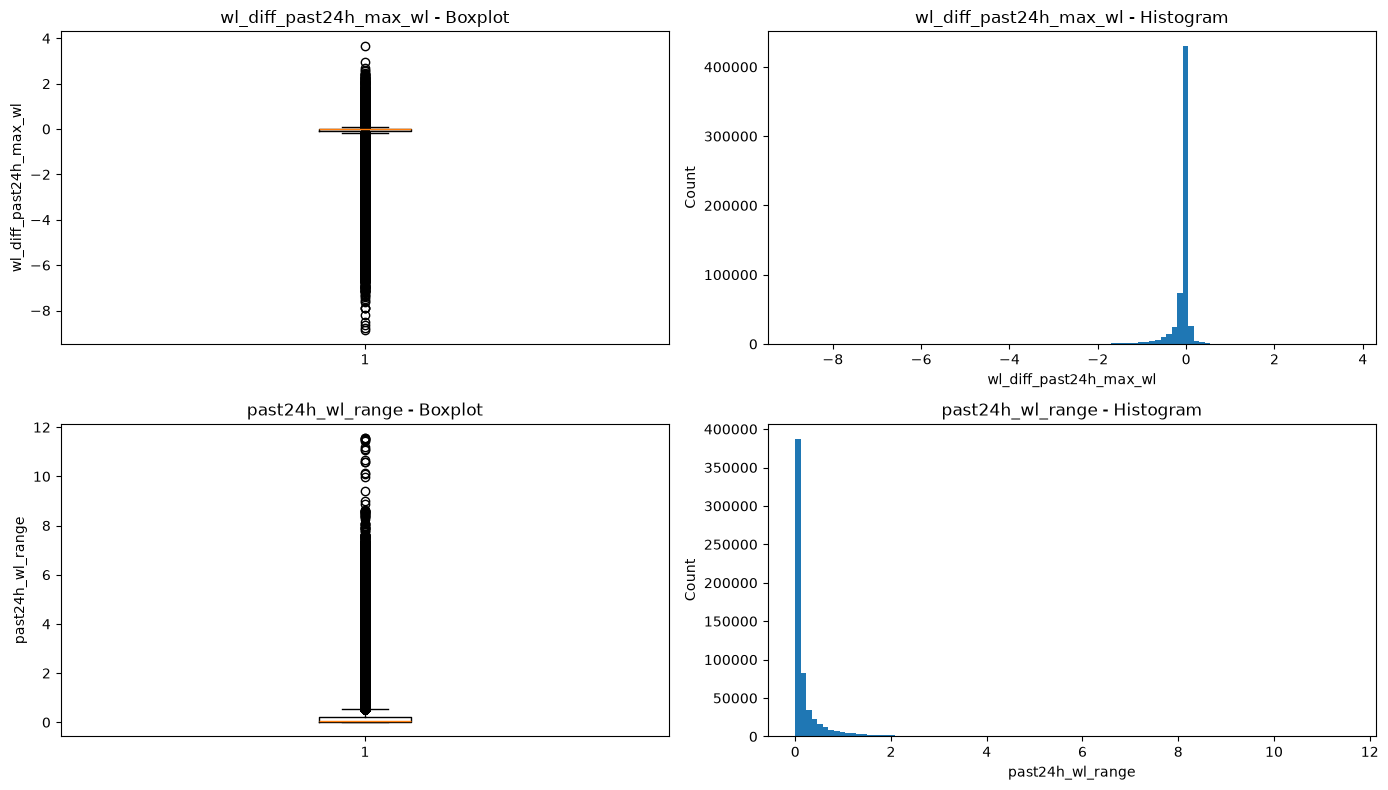

In [12]:
# ============================================================
# 3-2. 신규 A 파생변수 분포 확인: 이상치가 의심되므로
# ============================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for i, col in enumerate(new_feature_cols_A):

    # 1열: 박스플롯 (세로형)
    axes[i][0].boxplot(
        train_fe_A[col].dropna(),
        orientation='vertical'
    )
    axes[i][0].set_title(f'{col} - Boxplot')
    axes[i][0].set_ylabel(col)

    # 2열: 히스토그램
    axes[i][1].hist(
        train_fe_A[col],
        bins=100
    )
    axes[i][1].set_title(f'{col} - Histogram')
    axes[i][1].set_xlabel(col)
    axes[i][1].set_ylabel('Count')

plt.tight_layout()
plt.show()

In [13]:
train_fe_A.head()

,timestamp,station_id,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h,imerg_rain_1h,imerg_rain_6h,...,wl_diff_3h,wl_diff_6h,wl_diff_12h,wl_diff_24h,imerg_int_1to6h,imerg_int_6to24h,sfc_int_1to6h,sfc_int_6to24h,wl_diff_past24h_max_wl,past24h_wl_range
row_id,,,,,,,,,,,,,,,,,,,,,
TR_000222241,2100-01-01,ST0001,0.29,0.29,0.28,0.28,0.28,0.27,0.000,0.000,...,0.01,0.01,0.01,0.02,0.000,0.000000,0.0,0.0,0.00,0.02
TR_000288748,2100-01-01,ST0002,0.77,0.76,0.77,0.77,0.76,0.77,0.000,0.000,...,0.00,0.00,0.01,0.00,0.000,0.000000,0.0,0.0,0.00,0.01
TR_000737576,2100-01-01,ST0003,0.73,0.73,0.74,0.74,0.73,0.73,0.000,0.000,...,-0.01,-0.01,0.00,0.00,0.000,0.000000,0.0,0.0,-0.01,0.01
TR_000651952,2100-01-01,ST0004,1.01,1.01,1.01,1.01,1.01,1.01,0.000,0.000,...,0.00,0.00,0.00,0.00,0.000,0.000000,0.0,0.0,0.00,0.00
TR_000328380,2100-01-01,ST0005,1.01,1.01,1.01,1.01,1.03,1.06,3.018,7.493,...,0.00,0.00,-0.02,-0.05,0.895,0.000222,0.0,0.0,-0.05,0.05


In [20]:
# ============================================================
# 4. 신규 A 모델 학습용 데이터 준비
# ============================================================

# 신규 파생변수를 포함한 입력변수 구성
X_train_with_station = train_fe_A[
    num_cols_fe_A + ['station_id']
].copy()

# CatBoost 범주형 변수 처리
X_train_with_station['station_id'] = (
    X_train_with_station['station_id'].astype(str)
)

# 고정 Fold 매핑 파일 불러오기
kf_fold_fixed = pd.read_csv(
    PROJECT_ROOT / 'config' / '0_kf_event_fold_match.csv'
)

# event_id 기준 Fold 번호 연결 및 검증
print(train_fe_A['event_id'].map(
    kf_fold_fixed.set_index('event_id')['fold_num']
).value_counts().sort_index())

# 기존 OOF와 고정 Fold 배정 비교
print('Fold 불일치:', (
    train_kf_oof['fold_num'].reindex(train_fe_A.index)
    != train_fe_A['event_id'].map(
        kf_fold_fixed.set_index('event_id')['fold_num']
    )
).sum())

event_id
1    122996
2    123399
3    123399
4    123216
5    123283
Name: count, dtype: int64
Fold 불일치: 0


In [22]:
# ============================================================
# 5. 신규 A 파생변수 적용: CatBoost 5-Fold 교차검증
# ============================================================

# OOF 예측값 저장
kf_oof_pred_A = np.zeros(len(train_fe_A))
kf_results_A = []

# 고정 Fold 번호 연결
kf_groups = train_fe_A['event_id'].map(
    kf_fold_fixed.set_index('event_id')['fold_num']
)

# 5-Fold 모델링
for fold_num in range(1, 6):

    # Fold별 행 위치
    train_idx = np.where(kf_groups.to_numpy() != fold_num)[0]
    val_idx = np.where(kf_groups.to_numpy() == fold_num)[0]

    # Fold별 데이터 분할
    X_kf_tr = X_train_with_station.iloc[train_idx]
    X_kf_va = X_train_with_station.iloc[val_idx]

    y_kf_tr = y_train.iloc[train_idx]
    y_kf_va = y_train.iloc[val_idx]

    # 모델 정의
    model_cat_kf = CatBoostRegressor(
        random_state=42,
        iterations=3000,
        cat_features=['station_id']
    )

    # 모델 학습
    model_cat_kf.fit(
        X_kf_tr,
        y_kf_tr,
        eval_set=(X_kf_va, y_kf_va),
        early_stopping_rounds=100,
        verbose=200
    )

    # OOF 예측값 저장
    pred_va = model_cat_kf.predict(X_kf_va)
    kf_oof_pred_A[val_idx] = pred_va

    # Fold별 RMSE
    rmse_va = root_mean_squared_error(y_kf_va, pred_va)

    kf_results_A.append({
        'fold_num': fold_num,
        'rmse': rmse_va,
        'best_iteration': model_cat_kf.best_iteration_
    })

    print(f'Fold {fold_num} RMSE: {rmse_va:.6f}')
    print()

# ============================================================
# 6. 신규 A OOF 성능 확인
# ============================================================

print('신규 A OOF RMSE:', root_mean_squared_error(
    y_train, kf_oof_pred_A
))

print('기존 OOF RMSE:', root_mean_squared_error(
    train_kf_oof['y_kf_val'],
    train_kf_oof['y_kf_pred']
))

display(pd.DataFrame(kf_results_A))

Learning rate set to 0.068972
0:	learn: 0.3781992	test: 0.4352551	best: 0.4352551 (0)	total: 283ms	remaining: 14m 8s
200:	learn: 0.2184530	test: 0.2791157	best: 0.2791157 (200)	total: 29s	remaining: 6m 44s
400:	learn: 0.2055879	test: 0.2741831	best: 0.2741446 (394)	total: 56.4s	remaining: 6m 5s
600:	learn: 0.1980429	test: 0.2727918	best: 0.2726357 (575)	total: 1m 26s	remaining: 5m 43s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.2726356857
bestIteration = 575

Shrink model to first 576 iterations.
Fold 1 RMSE: 0.272636

Learning rate set to 0.068963
0:	learn: 0.4063757	test: 0.3167256	best: 0.3167256 (0)	total: 227ms	remaining: 11m 21s
200:	learn: 0.2451501	test: 0.1564817	best: 0.1564817 (200)	total: 27.4s	remaining: 6m 22s
400:	learn: 0.2318882	test: 0.1506637	best: 0.1506637 (400)	total: 55.2s	remaining: 5m 58s
600:	learn: 0.2235722	test: 0.1487515	best: 0.1487515 (600)	total: 1m 22s	remaining: 5m 29s
800:	learn: 0.2174379	test: 0.1479040	best: 0.1478953 (794

,fold_num,rmse,best_iteration
0,1,0.272636,575
1,2,0.147522,950
2,3,0.227189,2153
3,4,0.272373,687
4,5,0.218191,2544


In [24]:
# ============================================================
# 7. 신규 A 적용 전후 강우사상별 SSE 비교
# ============================================================

# 신규 A 예측값과 기존 OOF의 row_id 순서 일치
assert train_fe_A.index.equals(X_train_with_station.index)
assert train_fe_A.index.is_unique
assert train_kf_oof.index.is_unique

# 강우사상별 SSE 비교
event_sse_A = (
    pd.DataFrame({
        'event_id': train_fe_A['event_id'],
        'sse_base': train_kf_oof['resid_sq'].reindex(train_fe_A.index),
        'sse_A': (y_train.to_numpy() - kf_oof_pred_A) ** 2
    })
    .groupby('event_id')
    .agg(
        count=('sse_base', 'size'),
        sse_base=('sse_base', 'sum'),
        sse_A=('sse_A', 'sum')
    )
)

# SSE 감소량: 양수일수록 개선
event_sse_A['delta_sse'] = (
    event_sse_A['sse_base'] - event_sse_A['sse_A']
)

# SSE 개선율(%)
event_sse_A['improve_pct'] = (
    event_sse_A['delta_sse'] / event_sse_A['sse_base'] * 100
)

# 기존 SSE가 큰 상위 6개 강우사상 비교
display(
    event_sse_A
    .sort_values('sse_base', ascending=False)
    .head(6)
    .round(3)
)

# 전체 강우사상별 SSE 개선 현황
print('SSE 개선 사상 수:', (event_sse_A['delta_sse'] > 0).sum())
print('SSE 악화 사상 수:', (event_sse_A['delta_sse'] < 0).sum())
print('전체 SSE 감소량:', event_sse_A['delta_sse'].sum())

,count,sse_base,sse_A,delta_sse,improve_pct
event_id,,,,,
98,71567,7696.683,7724.796,-28.113,-0.365
90,24970,3795.924,3778.512,17.412,0.459
35,19967,3318.869,3201.611,117.258,3.533
97,7408,3212.074,3181.807,30.267,0.942
3,18059,2627.781,2651.377,-23.596,-0.898
89,25289,2286.620,2269.808,16.812,0.735


SSE 개선 사상 수: 57
SSE 악화 사상 수: 41
전체 SSE 감소량: 200.9555810632093


In [ ]:
# 신규 A 파생변수 실험 결과

# 과거 24시간 수위의 최대값 및 변동폭 관련 파생변수 2개를 추가한 결과, OOF RMSE는 0.232827에서 0.232126으로 약 0.30% 개선되었다.

# 98개 강우사상 중 57개에서 SSE가 감소했으나, 기존 SSE 상위 6개 사상 중 2개에서는 오히려 오차가 증가하였다. 특히 사상 35에서 전체 SSE 감소량의 약 58.4%가 발생하여 개선 효과의 일부가 특정 사상에 집중되었다.

# 결론: 신규 A 변수의 성능 개선 효과는 제한적이며, 고오차 강우사상에 대한 일관된 개선 효과가 확인되지 않았다. 현 단계에서는 채택을 보류하고 다른 고도화 가설을 검증한다.